# Fraud Classification: Imbalance, Scaling, SMOTE & Evaluation

**Intelligence Lab · Month 1 · Practical notebook 01**

In this notebook, you will build and evaluate a fraud classifier while practising:
- confusion matrix, precision, recall, F1-score and accuracy;
- train/test splitting without leakage;
- fitting `StandardScaler` on training data only;
- applying SMOTE only to training data;
- comparing a baseline with a resampled model;
- understanding the precision–recall trade-off.

**How to use:** Run the setup and data cells. In cells marked **Your turn**, write the missing code before looking up anything. Keep the test set untouched until evaluation.

You can open this notebook in Google Colab using the badge/link in the repository, or download it and run it locally in Jupyter.

In [1]:
# Install the one extra package used for SMOTE and leakage-safe pipelines
%pip -q install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    PrecisionRecallDisplay
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
print('Setup complete')

Setup complete


## 1. Create an imbalanced dataset

We will use a synthetic dataset so the notebook runs without downloading private or sensitive transaction data. The minority class represents fraud. These rows are simulated, not real transactions.

In [3]:
X, y = make_classification(
    n_samples=10_000,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    n_clusters_per_class=2,
    weights=[0.99, 0.01],
    flip_y=0.001,
    class_sep=1.0,
    random_state=RANDOM_STATE
)

feature_names = [
    'transaction_amount', 'transactions_per_hour', 'account_age_days',
    'distance_from_usual_km', 'failed_attempts', 'merchant_risk',
    'device_change_score', 'hour_of_day'
]
X = pd.DataFrame(X, columns=feature_names)
y = pd.Series(y, name='is_fraud')

print('Dataset shape:', X.shape)
print('\nClass counts:')
print(y.value_counts().rename(index={0:'Legitimate', 1:'Fraud'}))
print('\nFraud percentage:', round(y.mean() * 100, 2), '%')

Dataset shape: (10000, 8)

Class counts:
is_fraud
Legitimate    9895
Fraud          105
Name: count, dtype: int64

Fraud percentage: 1.05 %


### Checkpoint 1

1. Which class is the minority class?
2. Why could accuracy be misleading on this dataset?
3. What would a model that predicts every row as legitimate score on accuracy?

## 2. Split first — protect the test set

We split before learning preprocessing statistics or generating synthetic examples. `stratify=y` keeps the class proportions approximately consistent in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
print('\nTraining fraud rate:', round(y_train.mean() * 100, 2), '%')
print('Test fraud rate:', round(y_test.mean() * 100, 2), '%')

Training rows: 8000
Test rows: 2000

Training fraud rate: 1.05 %
Test fraud rate: 1.05 %


## 3. Baseline model — no SMOTE yet

First, establish a baseline. This model uses class-imbalance-unaware logistic regression. We will fit the scaler on training data only, then transform both sets with the same fitted scaler.

In [5]:
scaler_baseline = StandardScaler()

# Fit ONLY on training features
X_train_scaled = scaler_baseline.fit_transform(X_train)

# Transform test features using training-set statistics
X_test_scaled = scaler_baseline.transform(X_test)

baseline_model = LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_scaled, y_train)
baseline_pred = baseline_model.predict(X_test_scaled)

print('Baseline model trained.')

Baseline model trained.


In [6]:
def evaluate_classifier(y_true, y_pred, model_name):
    results = {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
    }
    print(pd.Series(results).to_string())
    print('\nConfusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_true, y_pred))
    return results

baseline_results = evaluate_classifier(y_test, baseline_pred, 'Baseline logistic regression')

model        Baseline logistic regression
accuracy                             0.99
precision                             1.0
recall                           0.047619
f1                               0.090909

Confusion matrix [[TN, FP], [FN, TP]]:
[[1979    0]
 [  20    1]]


### Your turn 1 — interpret the baseline

Write down:
- Is accuracy alone a useful summary here?
- How many fraud cases did the model miss? (Read FN from the confusion matrix.)
- For this bank scenario, which error is more costly: FP or FN? Explain your assumption.

## 4. Apply SMOTE correctly

SMOTE creates synthetic minority-class examples using nearby minority examples. Because it uses distances, scaling first is important for this dataset.

For this first demonstration, we will explicitly show the steps. The scaler is fitted only on the training set. SMOTE is applied only to the scaled training set. The test set is never resampled.

In [7]:
# Fit scaler on training data only
scaler_smote = StandardScaler()
X_train_scaled_smote = scaler_smote.fit_transform(X_train)
X_test_scaled_smote = scaler_smote.transform(X_test)

# Resample only the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled_smote, y_train
)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE: ', pd.Series(y_train_resampled).value_counts().to_dict())
print('Test set unchanged:', X_test_scaled_smote.shape, y_test.shape)

Before SMOTE: {0: 7916, 1: 84}
After SMOTE:  {0: 7916, 1: 7916}
Test set unchanged: (2000, 8) (2000,)


In [8]:
smote_model = LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE)
smote_model.fit(X_train_resampled, y_train_resampled)
smote_pred = smote_model.predict(X_test_scaled_smote)

smote_results = evaluate_classifier(y_test, smote_pred, 'Scaled + SMOTE + logistic regression')

model        Scaled + SMOTE + logistic regression
accuracy                                    0.758
precision                                0.036072
recall                                   0.857143
f1                                       0.069231

Confusion matrix [[TN, FP], [FN, TP]]:
[[1498  481]
 [   3   18]]


### Your turn 2 — compare the models

Compare baseline and SMOTE results:
1. Did recall improve?
2. What happened to precision?
3. Did accuracy increase or decrease?
4. Which model would you choose for a bank, and what operational cost would your choice create?

There is no universally best result. The right choice depends on the cost of missed fraud, false alarms, and investigation capacity.

## 5. Use a pipeline for safer model evaluation

For cross-validation and production-style workflows, put preprocessing and SMOTE inside an `imblearn` pipeline. This ensures each training fold learns its own scaling statistics and synthetic samples; validation/test rows are not used to fit those steps.

Here we fit the pipeline on the training set and evaluate once on the untouched test set.

In [9]:
safe_pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE))
])

safe_pipeline.fit(X_train, y_train)
pipeline_pred = safe_pipeline.predict(X_test)
pipeline_results = evaluate_classifier(y_test, pipeline_pred, 'Imbalanced-learn pipeline')

model        Imbalanced-learn pipeline
accuracy                         0.758
precision                     0.036072
recall                        0.857143
f1                            0.069231

Confusion matrix [[TN, FP], [FN, TP]]:
[[1498  481]
 [   3   18]]


## 6. Threshold experiment

A classifier can output probabilities. The default threshold is often 0.5, but we can change it to explore the precision–recall trade-off. Lower thresholds generally flag more examples as positive, often increasing recall while reducing precision.

In [10]:
fraud_probabilities = safe_pipeline.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.35, 0.50, 0.65, 0.80]:
    threshold_pred = (fraud_probabilities >= threshold).astype(int)
    threshold_rows.append({
        'threshold': threshold,
        'precision': precision_score(y_test, threshold_pred, zero_division=0),
        'recall': recall_score(y_test, threshold_pred, zero_division=0),
        'f1': f1_score(y_test, threshold_pred, zero_division=0),
        'fraud_alerts': int(threshold_pred.sum())
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results

,threshold,precision,recall,f1,fraud_alerts
0,0.20,0.017573,1.000000,0.034539,1195
1,0.35,0.023486,0.904762,0.045783,809
2,0.50,0.036072,0.857143,0.069231,499
3,0.65,0.043321,0.571429,0.080537,277
4,0.80,0.054264,0.333333,0.093333,129


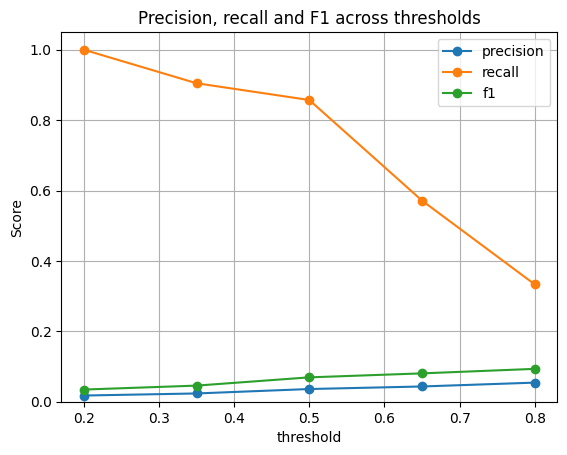

In [11]:
ax = threshold_results.plot(x='threshold', y=['precision', 'recall', 'f1'], marker='o')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Precision, recall and F1 across thresholds')
plt.grid(True)
plt.show()

### Your turn 3 — choose a threshold

Choose a threshold for a bank that strongly prioritises catching fraud. Use the table and explain:
- why you selected it;
- how many alerts it creates;
- what trade-off it makes between missed fraud and false alarms.

Do not choose a threshold from recall alone. Consider operational capacity and the costs of both error types.

## 7. Experiment 3 — class-weighted Logistic Regression

SMOTE changes the training data by generating synthetic minority-class examples. Another approach is to keep the original training rows and give mistakes on the minority class a larger penalty.

With `class_weight='balanced'`, Logistic Regression automatically assigns weights inversely related to class frequencies in the training data. This does not create new rows. It changes how strongly the model is penalised for mistakes on each class.

We will use a standard scikit-learn pipeline: fit the scaler on training data, transform features, and train the weighted classifier. The test set remains untouched.

In [ ]:
from sklearn.pipeline import Pipeline

weighted_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2_000,
        random_state=RANDOM_STATE
    ))
])

weighted_pipeline.fit(X_train, y_train)
weighted_pred = weighted_pipeline.predict(X_test)

weighted_results = evaluate_classifier(
    y_test,
    weighted_pred,
    'Class-weighted logistic regression'
)

### Your turn 4 — interpret class weighting

Compare this confusion matrix with the baseline and SMOTE results.

1. Did recall improve compared with the baseline?
2. How many false positives did it produce?
3. Is its precision better or worse than the SMOTE model?
4. Does it satisfy the bank's target of at least 90% recall and at most 100 alerts?
5. What trade-off did class weighting make?

Do not assume class weighting must outperform SMOTE. The result depends on the data and model.

In [ ]:
comparison = pd.DataFrame([
    {'model': 'Baseline logistic regression', **{k: baseline_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
    {'model': 'SMOTE + logistic regression', **{k: smote_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
    {'model': 'Class-weighted logistic regression', **{k: weighted_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
]).set_index('model')

comparison

### Important evaluation note

The three approaches above use the same held-out test set, so their results are directly comparable for this fixed experiment. In a more complete study, use stratified cross-validation with preprocessing and resampling fitted inside each training fold, tune decisions using validation data, and keep a final test set untouched until the end. Also remember that this is simulated data: it is useful for learning the workflow, not for estimating real-world bank performance.

## 8. Final reflection — record your evidence

Answer these in your own words before marking the notebook complete:

1. Why must the train/test split happen before fitting a scaler or applying SMOTE?
2. Why do we scale before SMOTE for distance-based neighbour selection?
3. Why must SMOTE never be applied to the test set?
4. What does precision tell a fraud operations team?
5. What does recall tell the team?
6. When can F1-score be insufficient as the only model-selection metric?
7. What would you test next: class weights, a different model, threshold tuning, or another resampling method? State a hypothesis.

### Completion checklist

- [ ] I ran every code cell successfully.
- [ ] I can explain each confusion-matrix value.
- [ ] I compared baseline and SMOTE results without relying on accuracy alone.
- [ ] I can explain why the test set remained untouched.
- [ ] I wrote a short conclusion and one next experiment.

**Research habit:** Record the random seed, data-generation settings, model configuration, metrics, and limitations whenever you report an experiment. Synthetic data is useful for practice, but it does not establish real-world fraud performance.